In [1]:
import numpy as np
import torch
import torch.nn.functional as F
from layers import Conv2D

conv = Conv2D(in_channels=3, out_channels=4, kernel_size=3, stride=2, padding=1, seed=0)
X = np.random.default_rng(1).normal(size=(2, 3, 9, 9))
out = conv.forward(X)

# reference via torch's functional conv2d using the exact same weights/bias
X_t = torch.tensor(X, dtype=torch.float64)
W_t = torch.tensor(conv.W, dtype=torch.float64)
b_t = torch.tensor(conv.b, dtype=torch.float64)
out_ref = F.conv2d(X_t, W_t, b_t, stride=2, padding=1).numpy()

print('shapes match:', out.shape == out_ref.shape, out.shape, out_ref.shape)
print('max abs diff vs torch:', np.abs(out - out_ref).max())

shapes match: True (2, 4, 5, 5) (2, 4, 5, 5)
max abs diff vs torch: 2.6645352591003757e-15


In [2]:
def check(padding, stride):
    conv = Conv2D(in_channels=3, out_channels=4, kernel_size=3, stride=stride, padding=padding, seed=0)
    X = np.random.default_rng(1).normal(size=(2, 3, 9, 9))
    out = conv.forward(X)
    dout = np.random.default_rng(2).normal(size=out.shape)
    dX, dW, db = conv.backward(dout)

    X_t = torch.tensor(X, dtype=torch.float64, requires_grad=True)
    W_t = torch.tensor(conv.W, dtype=torch.float64, requires_grad=True)
    b_t = torch.tensor(conv.b, dtype=torch.float64, requires_grad=True)
    out_t = F.conv2d(X_t, W_t, b_t, stride=stride, padding=padding)
    out_t.backward(torch.tensor(dout, dtype=torch.float64))

    print(f'padding={padding}, stride={stride}:')
    print('  dX diff:', np.abs(dX - X_t.grad.numpy()).max())
    print('  dW diff:', np.abs(dW - W_t.grad.numpy()).max())
    print('  db diff:', np.abs(db - b_t.grad.numpy()).max())

check(padding=0, stride=1)
check(padding=1, stride=1)
check(padding=1, stride=2)

padding=0, stride=1:
  dX diff: 5.329070518200751e-15
  dW diff: 1.0658141036401503e-14
  db diff: 1.7763568394002505e-15
padding=1, stride=1:
  dX diff: 7.105427357601002e-15
  dW diff: 2.1316282072803006e-14
  db diff: 5.329070518200751e-15
padding=1, stride=2:
  dX diff: 1.7763568394002505e-15
  dW diff: 3.552713678800501e-15
  db diff: 8.881784197001252e-16


In [3]:
from layers import MaxPool2D

def check(kernel_size, stride):
    pool = MaxPool2D(kernel_size=kernel_size, stride=stride)
    X = np.random.default_rng(1).normal(size=(2, 3, 9, 9))
    out = pool.forward(X)

    X_t = torch.tensor(X, dtype=torch.float64, requires_grad=True)
    out_t = F.max_pool2d(X_t, kernel_size=kernel_size, stride=stride)

    print(f'kernel={kernel_size}, stride={stride}: forward diff =', np.abs(out - out_t.detach().numpy()).max())

    dout = np.random.default_rng(2).normal(size=out.shape)
    dX = pool.backward(dout)
    out_t.backward(torch.tensor(dout, dtype=torch.float64))
    print('  backward diff:', np.abs(dX - X_t.grad.numpy()).max())

check(kernel_size=2, stride=2)
check(kernel_size=3, stride=2)

kernel=2, stride=2: forward diff = 0.0
  backward diff: 0.0
kernel=3, stride=2: forward diff = 0.0
  backward diff: 0.0


In [4]:
from layers import BatchNorm2D

def check(num_channels, shape):
    bn = BatchNorm2D(num_channels=num_channels)
    X = np.random.default_rng(1).normal(size=shape)
    out = bn.forward(X, training=True)

    bn_t = torch.nn.BatchNorm2d(num_channels, eps=bn.eps, momentum=bn.momentum, dtype=torch.float64)
    X_t = torch.tensor(X, dtype=torch.float64, requires_grad=True)
    out_t = bn_t(X_t)

    print(f'channels={num_channels}, shape={shape}:')
    print('  forward diff:', np.abs(out - out_t.detach().numpy()).max())
    print('  running_mean diff:', np.abs(bn.running_mean - bn_t.running_mean.numpy()).max())
    print('  running_var diff:', np.abs(bn.running_var - bn_t.running_var.numpy()).max())

    dout = np.random.default_rng(2).normal(size=out.shape)
    dX, dgamma, dbeta = bn.backward(dout)
    out_t.backward(torch.tensor(dout, dtype=torch.float64))

    print('  dX diff:', np.abs(dX - X_t.grad.numpy()).max())
    print('  dgamma diff:', np.abs(dgamma - bn_t.weight.grad.numpy()).max())
    print('  dbeta diff:', np.abs(dbeta - bn_t.bias.grad.numpy()).max())

check(num_channels=3, shape=(2, 3, 9, 9))
check(num_channels=4, shape=(5, 4, 6, 6))

channels=3, shape=(2, 3, 9, 9):
  forward diff: 4.440892098500626e-16
  running_mean diff: 5.204170427930421e-18
  running_var diff: 0.0005370851440886781
  dX diff: 8.881784197001252e-16
  dgamma diff: 3.552713678800501e-15
  dbeta diff: 2.6645352591003757e-15
channels=4, shape=(5, 4, 6, 6):
  forward diff: 8.881784197001252e-16
  running_mean diff: 5.204170427930421e-18
  running_var diff: 0.0005920500169127596
  dX diff: 8.881784197001252e-16
  dgamma diff: 3.1086244689504383e-15
  dbeta diff: 2.6645352591003757e-15


## Example: Conv2D + MaxPool2D on a real image

Hand-set edge/blur kernels applied to a digit from `sklearn.datasets.load_digits`, then downsampled with max pooling.

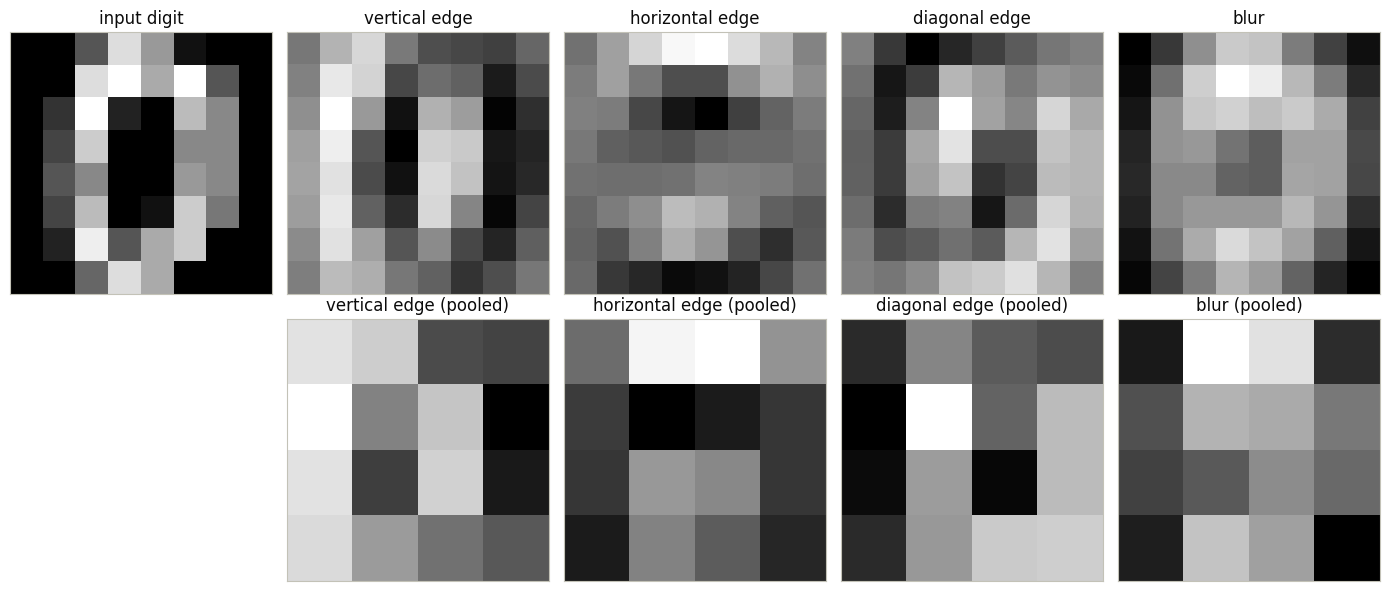

In [5]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

GRID = "#e1e0d9"
SPINE = "#c3c2b7"
TICK = "#898781"
TITLE = "#0b0b0b"
LABEL = "#52514e"
CATEGORICAL = ["#2a78d6", "#1baf7a", "#eda100", "#008300"]

def style_axes(ax):
    ax.set_facecolor("white")
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_color(SPINE)
    ax.tick_params(colors=TICK)
    ax.title.set_color(TITLE)

digits = load_digits()
image = digits.images[0]
X = image.reshape(1, 1, 8, 8).astype(np.float64)

conv = Conv2D(in_channels=1, out_channels=4, kernel_size=3, stride=1, padding=1)
kernels = {
    "vertical edge": np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]]),
    "horizontal edge": np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]]),
    "diagonal edge": np.array([[2, 1, 0], [1, 0, -1], [0, -1, -2]]),
    "blur": np.array([[1, 1, 1], [1, 1, 1], [1, 1, 1]]) / 9,
}
names = list(kernels.keys())
conv.W = np.stack([kernels[n] for n in names]).reshape(4, 1, 3, 3)
conv.b = np.zeros(4)

feature_maps = conv.forward(X)
pooled = MaxPool2D(kernel_size=2, stride=2).forward(feature_maps)

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
axes[0, 0].imshow(image, cmap="gray")
axes[0, 0].set_title("input digit", color=TITLE)
axes[1, 0].axis("off")
for i, name in enumerate(names):
    axes[0, i + 1].imshow(feature_maps[0, i], cmap="gray")
    axes[0, i + 1].set_title(name, color=TITLE)
    axes[1, i + 1].imshow(pooled[0, i], cmap="gray")
    axes[1, i + 1].set_title(f"{name} (pooled)", color=TITLE)
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
    style_axes(ax)
plt.tight_layout()
plt.show()

## Example: why BatchNorm2D matters

Three channels with deliberately mismatched scales/means. `BatchNorm2D` pulls all of them back to zero mean, unit variance regardless of their original range.

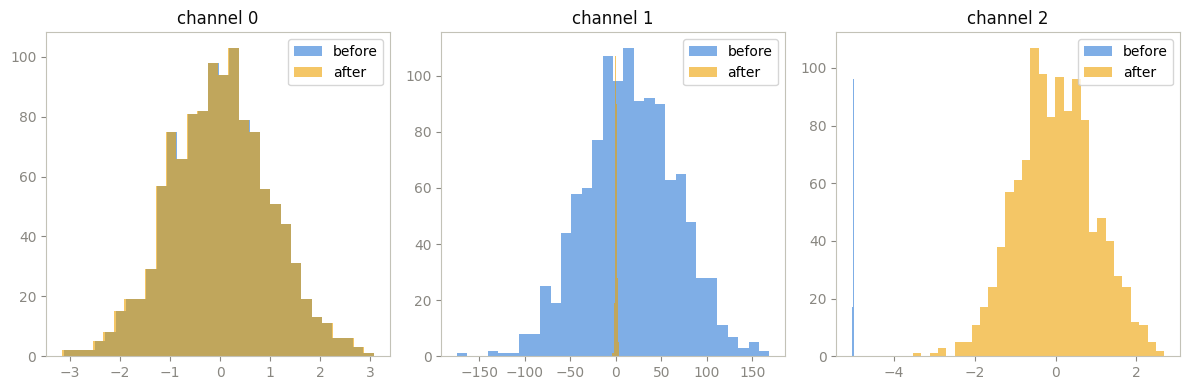

In [6]:
rng = np.random.default_rng(0)
batch = rng.normal(size=(32, 3, 6, 6))
batch[:, 0] = batch[:, 0] * 1
batch[:, 1] = batch[:, 1] * 50 + 20
batch[:, 2] = batch[:, 2] * 0.01 - 5

bn = BatchNorm2D(num_channels=3)
normalized = bn.forward(batch, training=True)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for c in range(3):
    axes[c].hist(batch[:, c].ravel(), bins=30, alpha=0.6, label="before", color=CATEGORICAL[0])
    axes[c].hist(normalized[:, c].ravel(), bins=30, alpha=0.6, label="after", color=CATEGORICAL[2])
    axes[c].set_title(f"channel {c}", color=TITLE)
    axes[c].legend()
    style_axes(axes[c])
plt.tight_layout()
plt.show()

## ReLU and Flatten

The two remaining primitives needed before a full network can be assembled: `ReLU` (elementwise, no learnable params) and `Flatten` (reshape between the conv stack and the dense stack).

In [7]:
from layers import ReLU, Flatten

rng = np.random.default_rng(5)
X = rng.normal(size=(4, 3, 5, 5))

relu = ReLU()
out = relu.forward(X)
dout = rng.normal(size=out.shape)
dX = relu.backward(dout)

X_t = torch.tensor(X, requires_grad=True)
out_t = torch.relu(X_t)
out_t.backward(torch.tensor(dout))
print('ReLU forward diff:', np.abs(out - out_t.detach().numpy()).max())
print('ReLU backward diff:', np.abs(dX - X_t.grad.numpy()).max())

flat = Flatten()
out2 = flat.forward(X)
dout2 = rng.normal(size=out2.shape)
dX2 = flat.backward(dout2)
print('Flatten shapes correct:', out2.shape == (4, 75) and dX2.shape == X.shape)

ReLU forward diff: 0.0
ReLU backward diff: 0.0
Flatten shapes correct: True


## LeNet-5

`Conv2D -> ReLU -> MaxPool2D -> Conv2D -> ReLU -> MaxPool2D -> Flatten -> Dense -> ReLU -> Dense -> ReLU -> Dense -> SoftmaxCrossEntropy`, the classic LeNet-5 architecture for 32x32 single-channel input, 10 output classes.

Verified by building an identical network in PyTorch, copying over the exact same weights, and comparing the forward pass, the loss, and every layer's weight/bias gradient after one backward pass.

In [8]:
from layers import LeNet

net = LeNet()
X = np.random.default_rng(1).normal(size=(4, 1, 32, 32))
y = np.random.default_rng(2).integers(0, 10, size=4)

logits = net.forward(X)
loss = net.loss_fn.forward(logits, y)
dlogits = net.loss_fn.backward()
_, grads = net.backward(dlogits)

X_t = torch.tensor(X, dtype=torch.float64, requires_grad=True)
y_t = torch.tensor(y, dtype=torch.long)

conv1_t = torch.nn.Conv2d(1, 6, 5, dtype=torch.float64)
conv2_t = torch.nn.Conv2d(6, 16, 5, dtype=torch.float64)
fc1_t = torch.nn.Linear(400, 120, dtype=torch.float64)
fc2_t = torch.nn.Linear(120, 84, dtype=torch.float64)
fc3_t = torch.nn.Linear(84, 10, dtype=torch.float64)

with torch.no_grad():
    conv1_t.weight.copy_(torch.tensor(net.conv1.W)); conv1_t.bias.copy_(torch.tensor(net.conv1.b))
    conv2_t.weight.copy_(torch.tensor(net.conv2.W)); conv2_t.bias.copy_(torch.tensor(net.conv2.b))
    fc1_t.weight.copy_(torch.tensor(net.fc1.W.T)); fc1_t.bias.copy_(torch.tensor(net.fc1.b))
    fc2_t.weight.copy_(torch.tensor(net.fc2.W.T)); fc2_t.bias.copy_(torch.tensor(net.fc2.b))
    fc3_t.weight.copy_(torch.tensor(net.fc3.W.T)); fc3_t.bias.copy_(torch.tensor(net.fc3.b))

out_t = F.relu(conv1_t(X_t))
out_t = F.max_pool2d(out_t, 2, 2)
out_t = F.relu(conv2_t(out_t))
out_t = F.max_pool2d(out_t, 2, 2)
out_t = out_t.reshape(out_t.shape[0], -1)
out_t = F.relu(fc1_t(out_t))
out_t = F.relu(fc2_t(out_t))
logits_t = fc3_t(out_t)

loss_t = F.cross_entropy(logits_t, y_t, reduction='mean')
loss_t.backward()

print('logits diff:', np.abs(logits - logits_t.detach().numpy()).max())
print('loss diff:', abs(loss - loss_t.item()))
print('conv1 dW/db diff:', np.abs(grads['conv1'][0] - conv1_t.weight.grad.numpy()).max(), np.abs(grads['conv1'][1] - conv1_t.bias.grad.numpy()).max())
print('conv2 dW/db diff:', np.abs(grads['conv2'][0] - conv2_t.weight.grad.numpy()).max(), np.abs(grads['conv2'][1] - conv2_t.bias.grad.numpy()).max())
print('fc1 dW/db diff:', np.abs(grads['fc1'][0] - fc1_t.weight.grad.numpy().T).max(), np.abs(grads['fc1'][1] - fc1_t.bias.grad.numpy()).max())
print('fc2 dW/db diff:', np.abs(grads['fc2'][0] - fc2_t.weight.grad.numpy().T).max(), np.abs(grads['fc2'][1] - fc2_t.bias.grad.numpy()).max())
print('fc3 dW/db diff:', np.abs(grads['fc3'][0] - fc3_t.weight.grad.numpy().T).max(), np.abs(grads['fc3'][1] - fc3_t.bias.grad.numpy()).max())

logits diff: 4.884981308350689e-15
loss diff: 1.3322676295501878e-15
conv1 dW/db diff: 1.3322676295501878e-15 1.5959455978986625e-16
conv2 dW/db diff: 6.661338147750939e-16 1.3877787807814457e-16
fc1 dW/db diff: 3.885780586188048e-16 5.204170427930421e-17
fc2 dW/db diff: 5.689893001203927e-16 4.85722573273506e-17
fc3 dW/db diff: 1.1102230246251565e-15 8.326672684688674e-17


## Training LeNet-5 on real data

`sklearn`'s digits (8x8) upsampled to 32x32 (nearest-neighbor repeat) to match LeNet's expected input size. Since these are naive nested-loop layers with no im2col/vectorization, this is deliberately a small run (300 training images, 40 steps, batch size 32) rather than a full training regime.

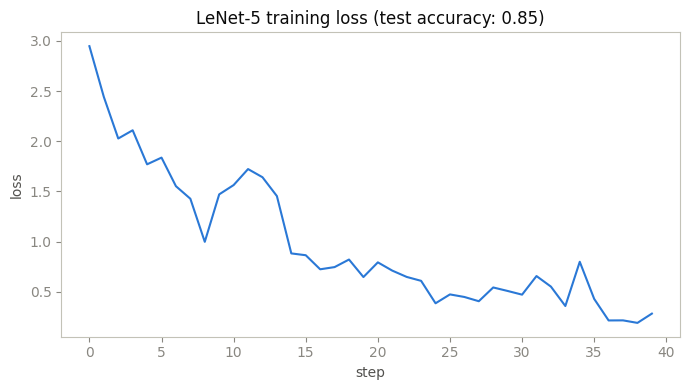

In [9]:
from sklearn.datasets import load_digits

digits = load_digits()
X_up = np.repeat(np.repeat(digits.images, 4, axis=1), 4, axis=2).reshape(-1, 1, 32, 32).astype(np.float64)
X_up = (X_up - X_up.mean()) / X_up.std()
y_all = digits.target

rng = np.random.default_rng(0)
idx = rng.permutation(len(X_up))
train_idx, test_idx = idx[:300], idx[300:360]
X_train, y_train = X_up[train_idx], y_all[train_idx]
X_test, y_test = X_up[test_idx], y_all[test_idx]

lenet = LeNet(num_classes=10)
batch_size = 32
losses = []
for step in range(40):
    b = rng.choice(len(X_train), size=batch_size, replace=False)
    losses.append(lenet.train_step(X_train[b], y_train[b], lr=0.05))

preds = lenet.predict(X_test)
acc = (preds == y_test).mean()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(losses, color=CATEGORICAL[0])
ax.set_title(f"LeNet-5 training loss (test accuracy: {acc:.2f})", color=TITLE)
ax.set_xlabel("step", color=LABEL)
ax.set_ylabel("loss", color=LABEL)
style_axes(ax)
plt.tight_layout()
plt.show()

## Visualizing what LeNet learned

Two classic CNN interpretability techniques, applied to the LeNet just trained above:

- **Filter visualization** — `conv1`'s learned kernels, shown directly as images since the first layer takes single-channel input (deeper layers mix channels and need more elaborate techniques to visualize).
- **Saliency mapping** ([Simonyan et al., 2013](https://arxiv.org/abs/1312.6034)) — the gradient of the predicted class's logit with respect to the input pixels. Large magnitude means "this pixel, if changed, would move the prediction the most" — i.e. which pixels the network is actually looking at.

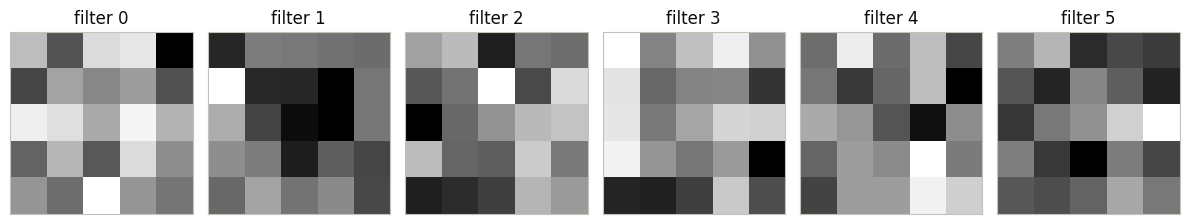

In [10]:
fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(lenet.conv1.W[i, 0], cmap="gray")
    ax.set_title(f"filter {i}", color=TITLE)
    ax.set_xticks([])
    ax.set_yticks([])
    style_axes(ax)
plt.tight_layout()
plt.show()

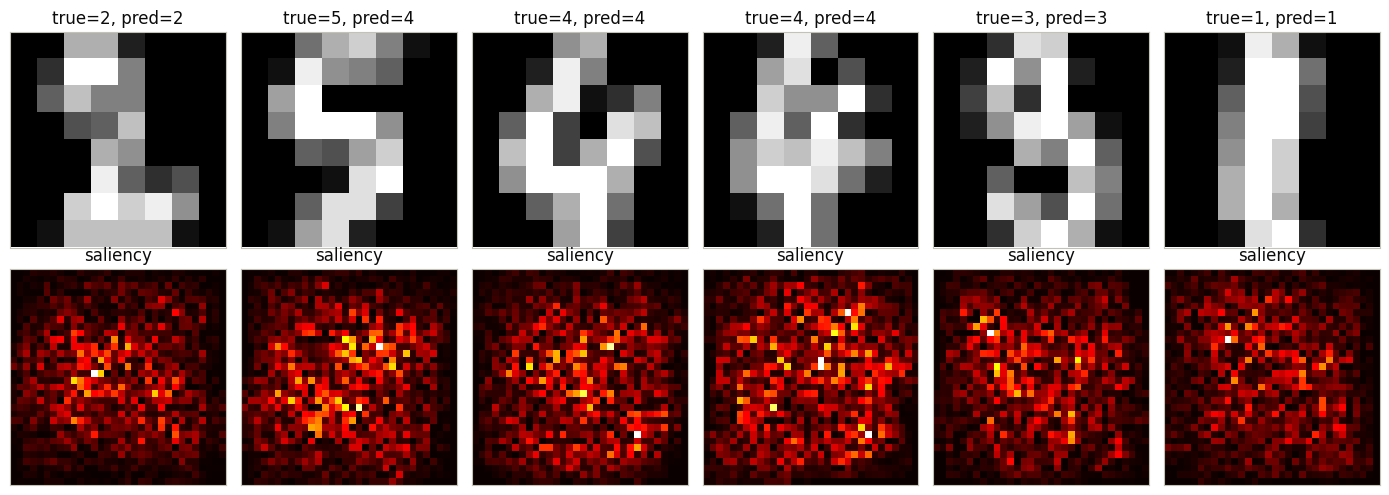

In [11]:
n_samples = 6
X_sample = X_test[:n_samples]
y_sample = y_test[:n_samples]

logits = lenet.forward(X_sample)
pred_classes = np.argmax(logits, axis=1)

dlogits = np.zeros_like(logits)
dlogits[np.arange(n_samples), pred_classes] = 1.0
dX, _ = lenet.backward(dlogits)
saliency = np.abs(dX[:, 0])

fig, axes = plt.subplots(2, n_samples, figsize=(14, 5))
for i in range(n_samples):
    axes[0, i].imshow(X_sample[i, 0], cmap="gray")
    axes[0, i].set_title(f"true={y_sample[i]}, pred={pred_classes[i]}", color=TITLE)
    axes[1, i].imshow(saliency[i], cmap="hot")
    axes[1, i].set_title("saliency", color=TITLE)
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
    style_axes(ax)
plt.tight_layout()
plt.show()

The filters don't look like the clean edge/blob detectors you'd see from a network trained on full ImageNet for hundreds of epochs, and the saliency is spread fairly diffusely across each digit rather than tightly outlining just the strokes. That's expected here, not a bug: this LeNet only saw 40 gradient steps over 300 images (each an 8x8 digit blown up to 32x32 via nearest-neighbor repeat, which itself introduces blocky structure at the pixel level). The technique — gradient of the predicted logit w.r.t. the input, verified above to match PyTorch's Conv2D/Dense gradients exactly — is correct; what it reveals here is simply an undertrained, low-resolution model. Training longer / on higher-resolution real images (real MNIST/CIFAR instead of upsampled 8x8 digits) would sharpen both.